# TP5 – Atelier CNN sur CIFAR-10 (dataset local)
Le dataset est lu depuis un dossier local organisé ainsi :
```
cifar10/
├── train/
│   ├── airplane/
│   ├── automobile/
│   └── ...
└── test/
    ├── airplane/
    └── ...
```

Found 50000 files belonging to 10 classes.
Found 10000 files belonging to 10 classes.
Classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train : (50000, 32, 32, 3) (50000,)
Test  : (10000, 32, 32, 3) (10000,)


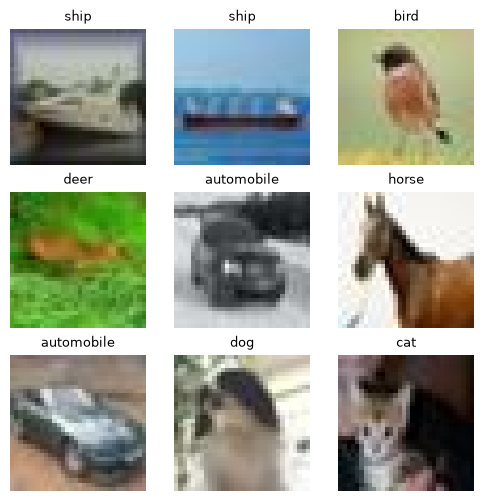

In [3]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Partie 1 – Chargement du dataset CIFAR-10 depuis le dossier local

DATA_DIR = "A:\\DeepLearning\\cifar10\\cifar10"                      # chemin vers le dossier cifar10
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")
IMG_SIZE = (32, 32)

def charger_dossier(chemin, shuffle):
    """Lit un dossier organisé par classes et renvoie (images, labels, noms_classes) en tableaux NumPy."""
    ds = tf.keras.utils.image_dataset_from_directory(
        chemin,
        labels="inferred",
        label_mode="int",          
        image_size=IMG_SIZE,
        batch_size=512,
        shuffle=shuffle,
        seed=42,
    )
    noms_classes = ds.class_names
    images, labels = [], []
    for x, y in ds:
        images.append(x.numpy().astype("uint8"))
        labels.append(y.numpy())
    return np.concatenate(images), np.concatenate(labels), noms_classes

x_train, y_train, class_names = charger_dossier(TRAIN_DIR, shuffle=True)
x_test, y_test, _ = charger_dossier(TEST_DIR, shuffle=False)

# Normalisation
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Classes :", class_names)
print("Train :", x_train.shape, y_train.shape)
print("Test  :", x_test.shape, y_test.shape)

# Affichage de quelques images
plt.figure(figsize=(6, 6))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis('off')
plt.show()

In [4]:
# Partie 2 – Construction du modèle CNN

num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,106 (1.21 MB)

 Trainable params: 315,914 (1.21 MB)

 Non-trainable params: 192 (768.00 B)

In [5]:
# Partie 3 – Compilation et Entraînement
# Compilation

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2
)
datagen.fit(x_train)

In [12]:
# Entraînement du modèle

history = model.fit(datagen.flow(x_train, y_train, batch_size=64),
                    validation_data=(x_test, y_test),
                    epochs=50,
                    callbacks=[early_stop])

Epoch 1/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 37s 47ms/step - accuracy: 0.6568 - loss: 0.9893 - val_accuracy: 0.6962 - val_loss: 0.8980
Epoch 2/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 83s 100ms/step - accuracy: 0.6604 - loss: 0.9839 - val_accuracy: 0.7303 - val_loss: 0.7808
Epoch 3/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 81s 104ms/step - accuracy: 0.6605 - loss: 0.9768 - val_accuracy: 0.6908 - val_loss: 0.9551
Epoch 4/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 75s 96ms/step - accuracy: 0.6656 - loss: 0.9677 - val_accuracy: 0.5712 - val_loss: 1.3643
Epoch 5/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 74s 95ms/step - accuracy: 0.6659 - loss: 0.9651 - val_accuracy: 0.6754 - val_loss: 0.9619
Epoch 6/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 75s 96ms/step - accuracy: 0.6703 - loss: 0.9583 - val_accuracy: 0.7069 - val_loss: 0.8434
Epoch 7/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 75s 96ms/step - accuracy: 0.6697 - loss: 0.9566 - val_accuracy: 0.6917 - val_loss: 0.8750


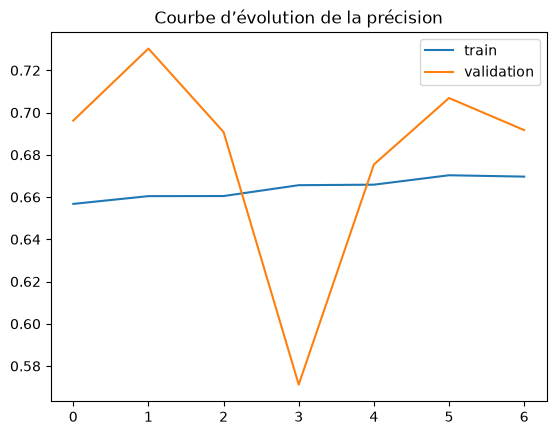

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7303 - loss: 0.7808
Accuracy sur test : 0.73


In [14]:
# Partie 4 – Évaluation et Visualisation
# Courbes de performance

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.legend()
plt.title('Courbe d’évolution de la précision')
plt.show()

# Évaluation finale

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Accuracy sur test : {test_acc:.2f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


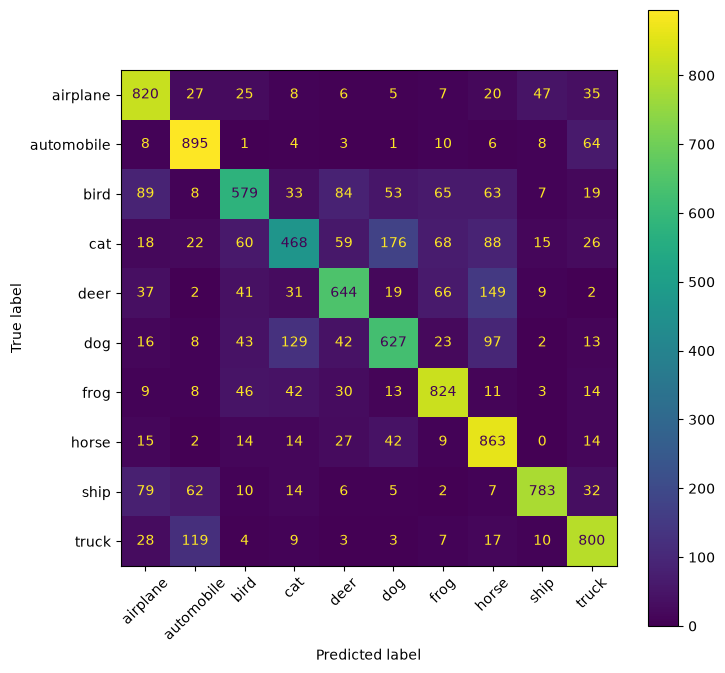

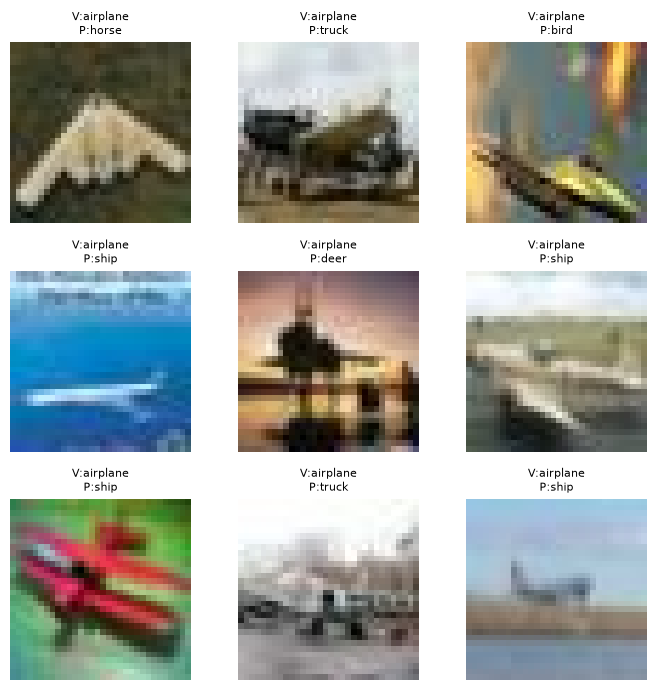

In [15]:
# Partie 5 – Analyse des erreurs
# 1. Prédiction et matrice de confusion

from sklearn.metrics import ConfusionMatrixDisplay

y_pred = np.argmax(model.predict(x_test), axis=1)

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=class_names,
                                        xticks_rotation=45, ax=ax)
plt.show()

# 2. Visualisation des erreurs typiques

errors = np.where(y_pred != y_test)[0][:9]
plt.figure(figsize=(7, 7))
for i, idx in enumerate(errors):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"V:{class_names[y_test[idx]]}\nP:{class_names[y_pred[idx]]}", fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()